# **Machine Learning Project Giovanni Lombardo A.A. 2024/25**

The aim of this project is to compare the performance of different regression models (Ridge Regression, Lasso Regression, Elastic Net Regression, PLS and MLP) in predicting  Nitrogen content of maize, sorghum, soybean (Glycine max), and camelina (Camelina sativa) sample leaves starting from Leaf-level hyperspectral reflectance data in the visible,
near-infrared, and shortwave infrared region (VIS-NIR-SWIR,
combined from 350–2500 nm).

## Import libraries

In [2]:
!pip install scikit-optimize
!pip install keras-tuner

In [3]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import warnings
from sklearn.metrics import  mean_squared_error
from sklearn.linear_model import Ridge,Lasso, ElasticNet
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
import sys, os
from sklearn.pipeline import make_pipeline
from skopt import BayesSearchCV
import skopt.space.space
from sklearn.model_selection import KFold
from scipy.signal import savgol_filter
from sklearn.cross_decomposition import PLSRegression
from tensorflow import keras
import keras_tuner as kt
from keras.models import Sequential
from keras.layers import Dense, Input, Normalization
import tensorflow as tf
from tensorflow.keras.optimizers import get as get_optimizer


2025-03-01 12:57:28.651254: I tensorflow/core/util/port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
2025-03-01 12:57:28.662447: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:477] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1740830248.676714   62524 cuda_dnn.cc:8310] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1740830248.680951   62524 cuda_blas.cc:1418] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
2025-03-01 12:57:28.695676: I tensorflow/core/platform/cpu_feature_guard.cc:210] This TensorFlow binary is optimized to use available CPU instr

## Dataset

Import dataset using pandas

In [4]:
df = pd.read_excel('LEAF_LEVEL_DATASET_Yufeng_Ge.xlsx')

### Analysis of the dataset

Get information on dataset

In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2905 entries, 0 to 2904
Columns: 2165 entries, ID to 2500
dtypes: float64(2160), int64(3), object(2)
memory usage: 48.0+ MB


Let's look at the top five rows

In [6]:
df.head()

,ID,Dataset,Year,Mg,S,LWC,chl,N,P,K,...,2491,2492,2493,2494,2495,2496,2497,2498,2499,2500
0,1,3,2019,0.28,0.23,73.152709,305.433333,2.83,0.36,1.96,...,0.032428,0.032477,0.032405,0.032253,0.032152,0.032126,0.031944,0.031711,0.031409,0.030644
1,2,3,2019,0.30,0.21,76.957071,221.733333,2.86,0.28,2.32,...,0.053516,0.053317,0.053086,0.052602,0.052398,0.052564,0.052472,0.052230,0.052255,0.052380
2,3,3,2019,0.25,0.22,73.882863,403.355556,2.97,0.29,1.56,...,0.048454,0.048271,0.048078,0.048033,0.047984,0.047991,0.047720,0.047180,0.047048,0.046832
3,4,3,2019,0.14,0.21,76.167315,371.722222,3.09,0.29,2.28,...,0.031391,0.031376,0.031267,0.031071,0.030832,0.030517,0.030229,0.029709,0.029611,0.029905
4,5,3,2019,0.16,0.20,74.066092,367.488889,2.89,0.36,2.21,...,0.030505,0.030413,0.030118,0.029635,0.029530,0.029575,0.029373,0.029288,0.029438,0.029592


The dataset contains the information about the reflectance value for every wavelenght from 350nm to 2500nm and nine relative leaf properties (chlorophyll, thickness, water content, nitrogen, phosphorus, potassium, calcium, magnesium, and sulfur).

For the aim of this project we wil consider only column 7 ("N") containing the information about nitrogen and the columns from 14 to the end containing reflectance values:

In [7]:
X = (df.iloc[:,14:]).values
Y = (df.iloc[:,7]).values
print(f"X-shape: {X.shape}")
print(f"Y-shape: {Y.shape}")

X-shape: (2905, 2151)
Y-shape: (2905,)


So, we **2905** samples and **2151** input features

###Preprocessing

Before feeding data to our algorithm, we apply some preprocessing techniques to producer higher quality data and increase predicton performance

####Spectral Binning

Spectral binning is a data processing technique used in spectroscopy and imaging to reduce the spectral resolution of a dataset by grouping adjacent wavelength into broader bins. The original data values which fall into a given small interval, a bin, are replaced by a value representative of that interval.

In this case we have chosen to bin **4** adjacent values and get the **mean** value.


By averaging multiple spectral channels, noise is reduced, making weak signals more detectable and thus improving the signal-to-noise ratio (SNR) at the cost of spectral detail. Indeed, binning reduces the amount of data, making storage and computational processing more efficient.



In [8]:
#Applying binning to columns
bin_width = 4
binned_columns = []
columns = df.iloc[:,14:].columns
i=0
while (i+1)*bin_width < len(columns):
      binned_columns.append(np.mean(columns[(i*bin_width):((i+1)*bin_width)]))
      i+=1

print(binned_columns)

[np.float64(351.5), np.float64(355.5), np.float64(359.5), np.float64(363.5), np.float64(367.5), np.float64(371.5), np.float64(375.5), np.float64(379.5), np.float64(383.5), np.float64(387.5), np.float64(391.5), np.float64(395.5), np.float64(399.5), np.float64(403.5), np.float64(407.5), np.float64(411.5), np.float64(415.5), np.float64(419.5), np.float64(423.5), np.float64(427.5), np.float64(431.5), np.float64(435.5), np.float64(439.5), np.float64(443.5), np.float64(447.5), np.float64(451.5), np.float64(455.5), np.float64(459.5), np.float64(463.5), np.float64(467.5), np.float64(471.5), np.float64(475.5), np.float64(479.5), np.float64(483.5), np.float64(487.5), np.float64(491.5), np.float64(495.5), np.float64(499.5), np.float64(503.5), np.float64(507.5), np.float64(511.5), np.float64(515.5), np.float64(519.5), np.float64(523.5), np.float64(527.5), np.float64(531.5), np.float64(535.5), np.float64(539.5), np.float64(543.5), np.float64(547.5), np.float64(551.5), np.float64(555.5), np.float64(

In [9]:
#Applying binning to values

bin_width = 4
binned_signals = np.zeros((X.shape[0], X.shape[1]//bin_width), dtype="float")

for k in range(len(X)):
    i = 0
    binned_signal = np.zeros((X.shape[1]//bin_width,), dtype="float")
    while (i+1)*bin_width < X.shape[1]:
        binned_signal[i] = np.mean(X[k,(i*bin_width):((i+1)*bin_width)])
        i+=1
    binned_signals[k] = binned_signal




####Savitzky-Golay filter

The Savitzky-Golay filter is a digital filter that smooths data points by fitting successive sub-sets of adjacent data points with a low-degree polynomial using the method of linear least squares. Its primary advantage lies in its ability to smooth data while preserving the features of the original signal, such as peaks and valleys, which might be lost with other smoothing techniques.

The Savitzky-Golay filter works by **sliding a window** of fixed size (one of its hyperparameters) over the data and fitting a polynomial to the points within this window (the **degree of the polynomial** is also a hyperparameter). The value of the polynomial at the central point of the window is then taken as the smoothed value. This process is repeated for each point in the data set, resulting in a smoothed signal.

In this case the window size is equal to **3** and the degree of the polynomial is equal to **1**.

In [14]:

filtered_signals = []
for binned_signal in binned_signals:
    filtered_signal = savgol_filter(binned_signal, window_length=3,polyorder=1)
    filtered_signals.append(filtered_signal)

X = pd.DataFrame(filtered_signals)
X.columns = binned_columns
X = X.iloc[:,7:]
X.head()

,379.5,383.5,387.5,391.5,395.5,399.5,403.5,407.5,411.5,415.5,...,2459.5,2463.5,2467.5,2471.5,2475.5,2479.5,2483.5,2487.5,2491.5,2495.5
0,0.039654,0.037832,0.037507,0.036458,0.036027,0.036487,0.037876,0.038727,0.039231,0.039796,...,0.040550,0.039234,0.037977,0.036745,0.035666,0.034723,0.033815,0.033042,0.032481,0.032109
1,0.062097,0.061372,0.062139,0.062398,0.064383,0.066246,0.067646,0.066140,0.066249,0.066827,...,0.062238,0.060916,0.059718,0.058528,0.057329,0.056237,0.055256,0.054357,0.053445,0.052509
2,0.053310,0.053222,0.053215,0.053486,0.054283,0.055185,0.055235,0.056235,0.056423,0.057529,...,0.056896,0.055454,0.054145,0.052962,0.051949,0.050819,0.049896,0.049006,0.048462,0.047880
3,0.037156,0.037369,0.036824,0.034772,0.034457,0.034386,0.034983,0.035871,0.035777,0.036719,...,0.039146,0.037781,0.036580,0.035438,0.034444,0.033527,0.032631,0.031930,0.031262,0.030722
4,0.037644,0.034901,0.035751,0.034865,0.035904,0.035375,0.036709,0.037590,0.038605,0.039918,...,0.037049,0.035883,0.034876,0.033906,0.033020,0.032229,0.031562,0.030965,0.030315,0.029584


In [15]:
X = X.values

##Models tests

In [11]:
from warnings import simplefilter
from sklearn.exceptions import ConvergenceWarning
simplefilter("ignore", category=ConvergenceWarning)


For all the models we are going to train we need to set tha values of some hyperparameters. Insted of using approaches like GridSearch or RandomSearch, here we are going to use the more powerful Bayesian Optimization.

Bayesian Optimization builds a probability model of the objective function and uses it to select hyperparameter to evaluate in the true objective function.

###RIDGE

Ridge requires only the hyperparameter alpha to be optimized. We use BayesianSearchCV with Kfold strategy for validation and mean squared error as metric.

In [12]:

seed = np.random.seed(777)
#Ripartition in training and test and
X_train, X_test, Y_train, Y_test = train_test_split(X, Y, test_size=0.25, random_state=seed)
ridge_reg_pipeline = make_pipeline(StandardScaler(),Ridge())

#Cross-validation strategy for BayesianSearch
kf = KFold(n_splits=5, shuffle=True,random_state=seed)

bayesian_estimator_ridge = BayesSearchCV(
                          ridge_reg_pipeline,
                          {'ridge__alpha': skopt.space.space.Real(1e-6,1e-2,'log-uniform')},
                          cv=kf,
                          scoring="neg_mean_squared_error",
                          n_jobs=-1,
                          verbose= False,
                            n_iter=50 )

bayesian_estimator_ridge.fit(X_train,Y_train)
best_alpha_ridge = float(bayesian_estimator_ridge.best_params_["ridge__alpha"])
score = -bayesian_estimator_ridge.score(X_test,Y_test)

print("Best alpha: " + str(best_alpha_ridge))
print("MSE: " + str(score))

Best alpha: 0.001122946183543809
MSE: 0.08916095309361091


After the computation of the optimal(it could not be the best one) value of alpha, we need to evaluate how the new obtained model performs and generalizes.

In this case, **Repeated Random Subampling** has been chosen as validation strategy. Also known as Monte Carlo cross-validation, repeated random subsampling cross-validation involves splitting the whole data into training data and test data. There are two version: the first mantains the train-test split percentage constant over the all iterations, the second one changes it. In this study, we used the first strategy.
The next step is to fit the model on the train data set in that iteration and calculate the accuracy of the fitted model on the test dataset. The iterations are repeated many times (100 in this case) and the average of all the test errors is taken to conclude how well the model performs.

In ever iteration we fix the split percentage, but thanks to a changing seed we shuffle the dataset, ensuring different sample will be filled in test and train sets every time.

In [13]:


trials = 100
random_cv = np.random.seed(777)
#Create seed list
seeds = np.random.choice(trials + 1, size=trials, replace= False)

MSE = np.zeros((trials), dtype="float")

for i in range(trials):
    X_train, X_test, Y_train, Y_test = train_test_split(X, Y, test_size=0.25, random_state=seeds[i])
    ridge = make_pipeline(StandardScaler(),Ridge(alpha=best_alpha_ridge))

    ridge.fit(X_train, Y_train)

    # Make predictions using the testing set
    Y_pred_ridge = ridge.predict(X_test)

    #Compute error
    MSE[i] = mean_squared_error(Y_test, Y_pred_ridge)

mean_MSE_ridge = np.mean(MSE)
std_ridge = np.std(MSE)
print("Obtained MSE: " + str(mean_MSE_ridge))
print("Standard Deviation: " + str(std_ridge))

Obtained MSE: 0.09063854560690679
Standard Deviation: 0.005748044556585979


Visualize the model using actual vs predicted plot, considering the last split of the dataset and last predictions.

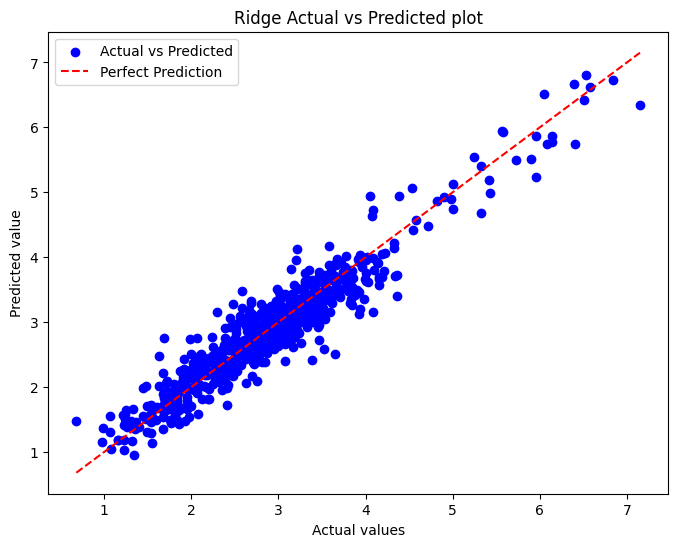

In [14]:
plt.figure(figsize=(8,6))
plt.scatter(Y_test, Y_pred_ridge, c='blue', label='Actual vs Predicted')
plt.plot([min(Y_test), max(Y_test)],
                        [min(Y_test), max(Y_test)], '--', c='red', label='Perfect Prediction')
plt.legend()
plt.xlabel("Actual values")
plt.ylabel("Predicted value")
plt.title("Ridge Actual vs Predicted plot")
plt.show()

###LASSO

The steps for LASSO regression are more or less identical to the ones of RIDGE

In [15]:


seed = np.random.seed(777)
#Ripartition in training and test and
X_train, X_test, Y_train, Y_test = train_test_split(X, Y, test_size=0.25, random_state=seed)
lasso_reg_pipeline = make_pipeline(StandardScaler(),Lasso())

#Cross-validation strategy for BayesianSearch
kf = KFold(n_splits=5, shuffle=True,random_state=seed)

bayesian_estimator_lasso = BayesSearchCV(
                          lasso_reg_pipeline,
                          {'lasso__alpha': skopt.space.space.Real(1e-6,1e-2,'log-uniform')},
                          cv=kf,
                          scoring="neg_mean_squared_error",
                          n_jobs=-1,
                          verbose= False,
                            n_iter=50 )

bayesian_estimator_lasso.fit(X_train,Y_train)
best_alpha_lasso = float(bayesian_estimator_lasso.best_params_["lasso__alpha"])
score = -bayesian_estimator_lasso.score(X_test,Y_test)

print("Best alpha: " + str(best_alpha_lasso))
print("MSE: " + str(score))

/home/demetra/Desktop/Demetra/venv_tf/lib/python3.12/site-packages/sklearn/linear_model/_coordinate_descent.py:697: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 1.990e+02, tolerance: 1.545e-01
  model = cd_fast.enet_coordinate_descent(
/home/demetra/Desktop/Demetra/venv_tf/lib/python3.12/site-packages/sklearn/linear_model/_coordinate_descent.py:697: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 2.018e+02, tolerance: 1.542e-01
  model = cd_fast.enet_coordinate_descent(
/home/demetra/Desktop/Demetra/venv_tf/lib/python3.12/site-packages/sklearn/linear_model/_coordinate_descent.py:697: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features

Best alpha: 0.000770158469240711
MSE: 0.21713369480286038


In [16]:

trials = 100
random_cv = np.random.seed(777)
#Create seed list
seeds = np.random.choice(trials + 1, size=trials, replace= False)

MSE = np.zeros((trials), dtype="float")

for i in range(trials):
    X_train, X_test, Y_train, Y_test = train_test_split(X, Y, test_size=0.25, random_state=seeds[i])
    lasso = make_pipeline(StandardScaler(),Lasso(alpha=best_alpha_lasso))

    lasso.fit(X_train, Y_train)

    # Make predictions using the testing set
    Y_pred_lasso = lasso.predict(X_test)

    #Compute error
    MSE[i] = mean_squared_error(Y_test, Y_pred_lasso)

mean_MSE_lasso = np.mean(MSE)
std_lasso = np.std(MSE)
print("Obtained MSE: " + str(mean_MSE_lasso))
print("Standard Deviation: " + str(std_lasso))

Obtained MSE: 0.21361461557641367
Standard Deviation: 0.013728309089709853


Visualize the model using actual vs predicted plot, considering the last split of the dataset and last predictions.

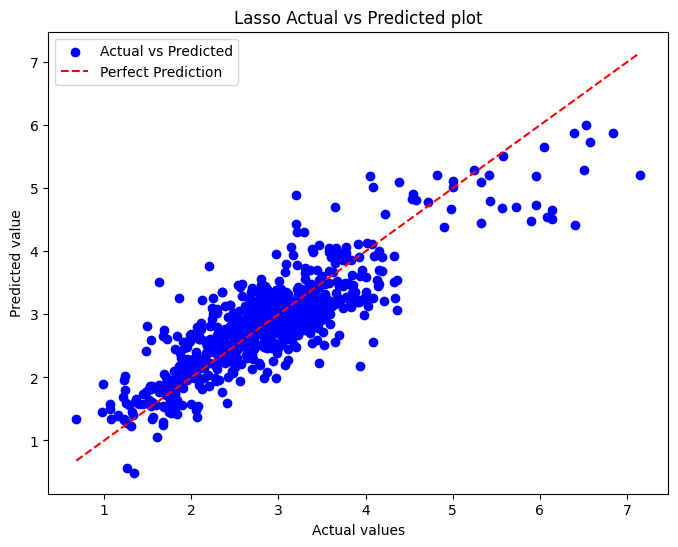

In [17]:
plt.figure(figsize=(8,6))
plt.scatter(Y_test, Y_pred_lasso, c='blue', label='Actual vs Predicted')
plt.plot([min(Y_test), max(Y_test)],
                        [min(Y_test), max(Y_test)], '--', c='red', label='Perfect Prediction')
plt.legend()
plt.xlabel("Actual values")
plt.ylabel("Predicted value")
plt.title("Lasso Actual vs Predicted plot")
plt.show()

###ELASTIC NET

For elastic net, the search space will change because we need to tune also **l1_ratio** i.e. the mixing parameter.

In [18]:

seed = np.random.seed(777)
#Ripartition in training and test and
X_train, X_test, Y_train, Y_test = train_test_split(X, Y, test_size=0.25, random_state=seed)
elastic_reg_pipeline = make_pipeline(StandardScaler(),ElasticNet())

#Cross-validation strategy for BayesianSearch
kf = KFold(n_splits=5, shuffle=True,random_state=seed)

bayesian_estimator_elastic = BayesSearchCV(
                          elastic_reg_pipeline,
                          {'elasticnet__alpha':  skopt.space.space.Real(1e-6,1e-2,'log-uniform'),
                          'elasticnet__l1_ratio': skopt.space.space.Real(0.1,1,'uniform')},
                          cv=kf,
                          scoring="neg_mean_squared_error",
                          n_jobs=-1,
                          verbose= False,
                            n_iter=50 )

bayesian_estimator_elastic.fit(X_train,Y_train)
best_alpha_elastic = float(bayesian_estimator_elastic.best_params_["elasticnet__alpha"])
best_l1_elastic = float(bayesian_estimator_elastic.best_params_["elasticnet__l1_ratio"])
score = -bayesian_estimator_elastic.score(X_test,Y_test)

print("Best alpha: " + str(best_alpha_elastic))
print("Best l1_ratio: " + str(best_l1_elastic))
print("MSE: " + str(score))

/home/demetra/Desktop/Demetra/venv_tf/lib/python3.12/site-packages/sklearn/linear_model/_coordinate_descent.py:697: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 1.986e+02, tolerance: 1.543e-01
  model = cd_fast.enet_coordinate_descent(
/home/demetra/Desktop/Demetra/venv_tf/lib/python3.12/site-packages/sklearn/linear_model/_coordinate_descent.py:697: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 1.957e+02, tolerance: 1.529e-01
  model = cd_fast.enet_coordinate_descent(
/home/demetra/Desktop/Demetra/venv_tf/lib/python3.12/site-packages/sklearn/linear_model/_coordinate_descent.py:697: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features

Best alpha: 0.004327347008533212
Best l1_ratio: 0.1
MSE: 0.21645658552503041


In [19]:

trials = 100
random_cv = np.random.seed(777)
#Create seed list
seeds = np.random.choice(trials + 1, size=trials, replace= False)

MSE = np.zeros((trials), dtype="float")

for i in range(trials):
    X_train, X_test, Y_train, Y_test = train_test_split(X, Y, test_size=0.25, random_state=seeds[i])
    elastic = make_pipeline(StandardScaler(),ElasticNet(alpha=best_alpha_elastic,l1_ratio=best_l1_elastic))

    elastic.fit(X_train, Y_train)

    # Make predictions using the testing set
    Y_pred_elastic = elastic.predict(X_test)

    #Compute error
    MSE[i] = mean_squared_error(Y_test, Y_pred_elastic)

mean_MSE_elastic = np.mean(MSE)
std_elastic = np.std(MSE)
print("Obtained MSE: " + str(mean_MSE_elastic))
print("Standard Deviation: " + str(std_elastic))

Obtained MSE: 0.20012258777683198
Standard Deviation: 0.014182082962614142


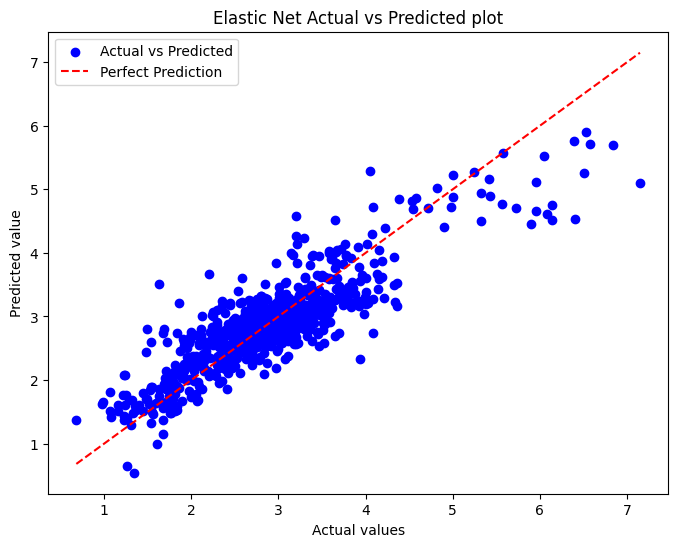

In [20]:
plt.figure(figsize=(8,6))
plt.scatter(Y_test, Y_pred_elastic, c='blue', label='Actual vs Predicted')
plt.plot([min(Y_test), max(Y_test)],
                        [min(Y_test), max(Y_test)], '--', c='red', label='Perfect Prediction')
plt.legend()
plt.xlabel("Actual values")
plt.ylabel("Predicted value")
plt.title("Elastic Net Actual vs Predicted plot")
plt.show()

###PLS

In [21]:

if not sys.warnoptions:
    warnings.simplefilter("ignore")
    os.environ["PYTHONWARNINGS"] = "ignore"


seed = np.random.seed(777)
#Ripartition in training and test and
X_train, X_test, Y_train, Y_test = train_test_split(X, Y, test_size=0.25, random_state=seed)
pls_reg_pipeline = make_pipeline(StandardScaler(),PLSRegression())

#Cross-validation strategy for BayesianSearch
kf = KFold(n_splits=5, shuffle=True,random_state=seed)

bayesian_estimator_pls = BayesSearchCV(
                          pls_reg_pipeline,
                          {'plsregression__n_components':skopt.space.space.Integer(1,100)},
                          cv=kf,
                          scoring="neg_mean_squared_error",
                          n_jobs=-1,
                          verbose= False,
                            n_iter=50 )

bayesian_estimator_pls.fit(X_train,Y_train)
n_components_pls = float(bayesian_estimator_pls.best_params_["plsregression__n_components"])

score = -bayesian_estimator_pls.score(X_test,Y_test)

print("No. of components: " + str(n_components_pls))
print("MSE: " + str(score))

No. of components: 68.0
MSE: 0.0945165474179261


In [22]:


trials = 100
random_cv = np.random.seed(777)
#Create seed list
seeds = np.random.choice(trials + 1, size=trials, replace= False)

MSE = np.zeros((trials), dtype="float")

for i in range(trials):
    X_train, X_test, Y_train, Y_test = train_test_split(X, Y, test_size=0.25, random_state=seeds[i])
    pls = make_pipeline(StandardScaler(),PLSRegression(n_components=int(n_components_pls)))

    pls.fit(X_train, Y_train)

    # Make predictions using the testing set
    Y_pred_pls = pls.predict(X_test)

    #Compute error
    MSE[i] = mean_squared_error(Y_test, Y_pred_pls)

mean_MSE_pls = np.mean(MSE)
std_pls = np.std(MSE)
print("Obtained MSE: " + str(mean_MSE_pls))
print("Standard Deviation: " + str(std_pls))

Obtained MSE: 0.09259265820799595
Standard Deviation: 0.005819802091392347


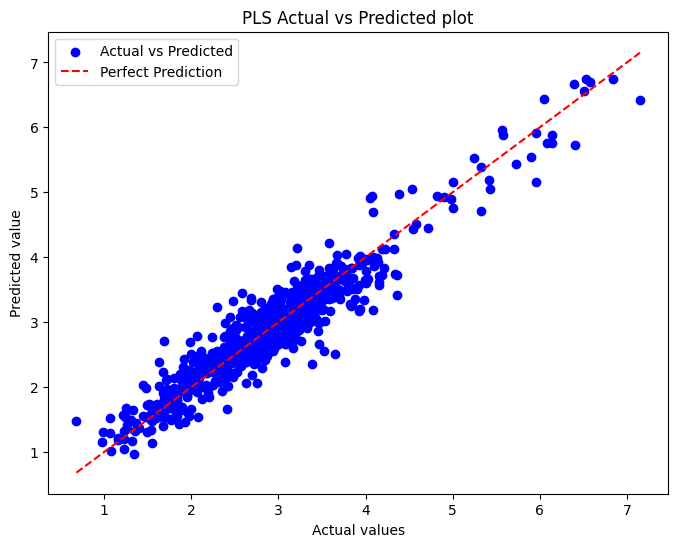

In [23]:
plt.figure(figsize=(8,6))
plt.scatter(Y_test, Y_pred_pls, c='blue', label='Actual vs Predicted')
plt.plot([min(Y_test), max(Y_test)],
                        [min(Y_test), max(Y_test)], '--', c='red', label='Perfect Prediction')
plt.legend()
plt.xlabel("Actual values")
plt.ylabel("Predicted value")
plt.title("PLS Actual vs Predicted plot")
plt.show()

###MLP

Bayseian Optimization

In [16]:

def model_builder(hp):
  
  max_n_layer = 8
  neurons = []
  for i in range(max_n_layer):
    neurons.append(hp.Int(f"n_neurons_{i}", min_value=2, max_value=1024, sampling="log"))
  hp_hidden = hp.Int('n_hidden', min_value=1, max_value=8)
  hp_learning_rate = hp.Float('learning_rate',min_value=1e-5, max_value=1, sampling="log")
  hp_optimizers = hp.Choice('optimizer', values = ["SGD","RMSprop","Adam"])
  optimizer = get_optimizer(hp_optimizers)
  optimizer.learning_rate = hp_learning_rate

  model = Sequential()
  model.add(Input(shape=X[0].shape))
  for k in range(hp_hidden):
    model.add(keras.layers.Dense(units=neurons[k], activation="relu"))

  model.add(keras.layers.Dense(1))


  model.compile(optimizer=hp_optimizers,
                loss="mean_absolute_error",
                metrics=["MeanSquaredError"])

  return model

Create Tuner

In [17]:

tuner = kt.BayesianOptimization(model_builder,
                     objective=kt.Objective("val_loss", direction="min"),
                     seed = 777,
                      max_trials = 100, 
                      overwrite=True,
                      directory="var_layer_neurons", project_name="MLProject"
)


2025-03-01 12:59:44.209081: E external/local_xla/xla/stream_executor/cuda/cuda_driver.cc:152] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: CUDA_ERROR_NO_DEVICE: no CUDA-capable device is detected


Start Search

In [18]:
X_train, X_test, Y_train, Y_test = train_test_split(X, Y, test_size=0.25, random_state=777)

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

stop_early = tf.keras.callbacks.EarlyStopping(monitor='val_loss', patience=10)

tuner.search(X_train, Y_train, epochs=9999, validation_split=0.2, callbacks=[stop_early])

# Get the optimal hyperparameters
best_hps=tuner.get_best_hyperparameters(num_trials=1)[0]

print(best_hps)


Trial 100 Complete [00h 00m 06s]
val_loss: 0.34478744864463806

Best val_loss So Far: 0.31992727518081665
Total elapsed time: 00h 15m 52s


Evaluate best model

In [19]:
best_model = tuner.hypermodel.build(best_hps)
best_model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_8 (Dense)                 │ (None, 334)            │       177,354 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_9 (Dense)                 │ (None, 18)             │         6,030 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_10 (Dense)                │ (None, 9)              │           171 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_11 (Dense)                │ (None, 800)            │         8,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_12 (Dense)                │ (None, 45)             │        36,045 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_13 (Dense)                │ (None, 13)             │           598 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_14 (Dense)                │ (None, 232)            │         3,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_15 (Dense)                │ (None, 47)             │        10,951 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_16 (Dense)                │ (None, 1)              │            48 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 242,445 (947.05 KB)

 Trainable params: 242,445 (947.05 KB)

 Non-trainable params: 0 (0.00 B)

In [24]:
best_hps.get('learning_rate')

1.5221891038371696e-05

In [20]:

trials = 100
random_cv = np.random.seed(777)
#Create seed list
seeds = np.random.choice(trials + 1, size=trials, replace= False)

MSE = np.zeros((trials), dtype="float")

for i in range(trials):
    optimizer = get_optimizer(best_hps.get('optimizer'))
    optimizer.learning_rate = best_hps.get('learning_rate')
    best_model.compile(optimizer=optimizer,loss="mean_absolute_error",
                metrics=["MeanSquaredError"])

    X_train, X_test, Y_train, Y_test = train_test_split(X, Y, test_size=0.25, random_state=seeds[i])

    scaler = StandardScaler()
    X_train = scaler.fit_transform(X_train)
    X_test = scaler.transform(X_test)


    best_model.fit(X_train, Y_train, epochs=9999, validation_split=0.2, callbacks=[stop_early])

    # Make predictions using the testing set
    Y_pred_mlp = best_model.predict(X_test)

    #Compute error
    MSE[i] = mean_squared_error(Y_test, Y_pred_mlp)

mean_MSE_mlp = np.mean(MSE)
std_mlp = np.std(MSE)
print("Obtained MSE: " + str(mean_MSE_mlp))
print("Standard Deviation: " + str(std_mlp))

Epoch 1/9999
55/55 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - MeanSquaredError: 9.2743 - loss: 2.8886 - val_MeanSquaredError: 9.0595 - val_loss: 2.8632
Epoch 2/9999
55/55 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - MeanSquaredError: 8.7503 - loss: 2.8103 - val_MeanSquaredError: 8.1029 - val_loss: 2.6878
Epoch 3/9999
55/55 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - MeanSquaredError: 7.5930 - loss: 2.5751 - val_MeanSquaredError: 4.6339 - val_loss: 1.8502
Epoch 4/9999
55/55 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - MeanSquaredError: 4.2566 - loss: 1.7255 - val_MeanSquaredError: 2.9272 - val_loss: 1.3874
Epoch 5/9999
55/55 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - MeanSquaredError: 3.0945 - loss: 1.4065 - val_MeanSquaredError: 2.7403 - val_loss: 1.3351
Epoch 6/9999
55/55 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - MeanSquaredError: 3.1087 - loss: 1.4128 - val_MeanSquaredError: 2.5717 - val_loss: 1.2913
Epoch 7/9999
55/55 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - MeanSquaredError: 2.7301 - loss: 1.3162 - val_MeanSquaredError: 2.4072 - val_loss:

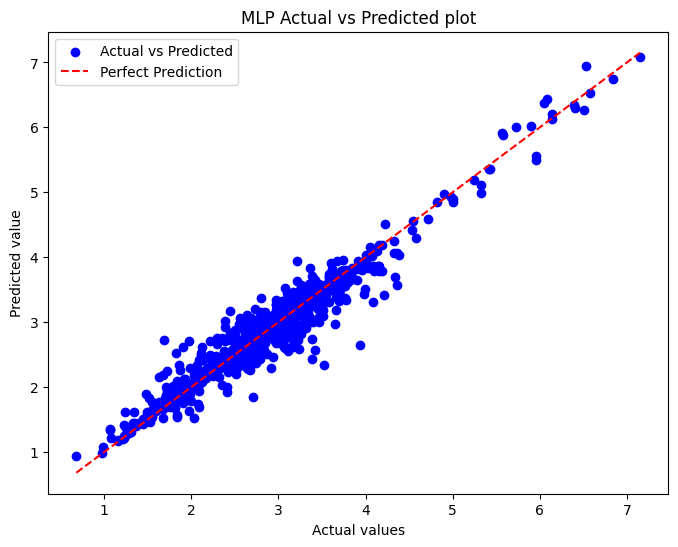

In [21]:
plt.figure(figsize=(8,6))
plt.scatter(Y_test, Y_pred_mlp, c='blue', label='Actual vs Predicted')
plt.plot([min(Y_test), max(Y_test)],
                        [min(Y_test), max(Y_test)], '--', c='red', label='Perfect Prediction')
plt.legend()
plt.xlabel("Actual values")
plt.ylabel("Predicted value")
plt.title("MLP Actual vs Predicted plot")
plt.show()

##Final Comparison

NameError: name 'mean_MSE_ridge' is not defined

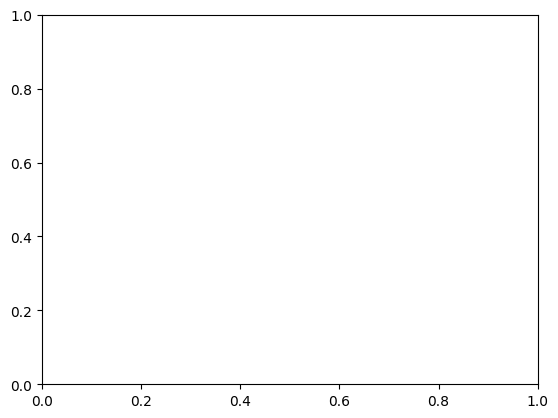

In [22]:

fig, ax = plt.subplots()


models = ('Ridge', 'Lasso', 'Elastic Net', 'PLS', 'MLP')
y_pos = np.arange(len(models))
performance = [mean_MSE_ridge,mean_MSE_lasso,mean_MSE_elastic,mean_MSE_pls,mean_MSE_mlp]
error = [std_ridge,std_lasso,std_elastic,std_pls,std_mlp]

ax.barh(y_pos, performance, xerr=error, align='center')
ax.set_yticks(y_pos, labels=models)
ax.invert_yaxis()  # labels read top-to-bottom
ax.set_xlabel('MSE')
ax.set_title('Models errors comparison')

plt.show()